In [ ]:
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
from tqdm.notebook import tqdm
from sklearn.model_selection import train_test_split
from sklearn.metrics import average_precision_score, accuracy_score, confusion_matrix, classification_report
import os
from torch.utils.data import TensorDataset, DataLoader
import torch.optim as optim
from timeit import default_timer as timer
from baselineModel import BaselineModel
import copy

if torch.cuda.is_available():
    device = "cuda" # Use NVIDIA GPU (if available)
elif torch.backends.mps.is_available():
    device = "mps" # Use Apple Silicon GPU (if available)
else:
    device = "cpu" # Default to CPU if no GPU is available
print(device)

random_state = 12
np.random.seed(random_state)
torch.manual_seed(random_state)

cpu


Now we will train a model that will predict a 'good' VS a 'bad' nodule.

## Initialize model

In [2]:
model = BaselineModel()
print(model)

BaselineModel(
  (features): Sequential(
    (0): Conv3d(1, 64, kernel_size=(3, 5, 5), stride=(1, 1, 1))
    (1): ReLU()
    (2): MaxPool3d(kernel_size=3, stride=3, padding=0, dilation=1, ceil_mode=False)
    (3): Dropout(p=0.2, inplace=False)
    (4): Conv3d(64, 64, kernel_size=(3, 5, 5), stride=(1, 1, 1))
    (5): ReLU()
    (6): MaxPool3d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (7): Dropout(p=0.2, inplace=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=6400, out_features=600, bias=True)
    (2): ReLU()
    (3): Linear(in_features=600, out_features=1, bias=True)
  )
)


## Make data ready for training

### Getting the labels

In [3]:
df = pd.read_csv("metadata.csv")

labels = df["label"].values
print(labels)

[1 1 0 ... 1 0 0]


Remove the scores that are not sure (done with Claude AI)

In [4]:
df = pd.read_csv("metadata.csv")

# remove nodules with mean malignancy exactly 3 ("indeterminate"): these are ambiguous labels
# no reset_index: df.index must keep pointing to the right row in X_all.npy
df = df[~df["mean_malignancy"].between(2.5, 3.5)]

labels = df["label"].values
print(len(df), "nodules left, share 'bad':", labels.mean())

1281 nodules left, share 'bad': 0.3013270882123341


### Splitting the data

We need to split on patients because otherwise we could have data leakage:
<br>
First we take 15% for testing, then we take 15% of the train data for validation

In [5]:
patients = df["patient_id"].unique().to_numpy()

temp_patients, test_patients = train_test_split(patients, test_size=0.15, random_state=random_state)
train_patients, val_patients = train_test_split(temp_patients, test_size=0.15, random_state=random_state)

# get the df with the right patient id
train_df = df[df["patient_id"].isin(train_patients)]
val_df = df[df["patient_id"].isin(val_patients)]
test_df = df[df["patient_id"].isin(test_patients)]

# one patient can have multiple nodules, so multiple samples
train_files, y_train = train_df["patch_path"].values, train_df["label"].values
val_files, y_val = val_df["patch_path"].values, val_df["label"].values
test_files, y_test = test_df["patch_path"].values, test_df["label"].values

print("Patiënts:", len(train_patients), len(val_patients), len(test_patients))
print("Samples:", len(train_files), len(val_files), len(test_files))
print("Amount positief:", y_train.mean(), y_val.mean(), y_test.mean())

Patiënts: 462 82 97
Samples: 918 166 197
Amount positief: 0.28322440087145967 0.3313253012048193 0.3604060913705584


Then we load the data:

In [6]:
X_train = np.array([np.load(f) for f in tqdm(train_files)])
X_val   = np.array([np.load(f) for f in tqdm(val_files)])
X_test  = np.array([np.load(f) for f in tqdm(test_files)])

  0%|          | 0/918 [00:00<?, ?it/s]

  0%|          | 0/166 [00:00<?, ?it/s]

  0%|          | 0/197 [00:00<?, ?it/s]

To tensors:
<br>
The unsqueeze is because conv3 want: (batch, channels, depth, height, width)

In [7]:
X_train = torch.tensor(X_train, dtype=torch.float32).unsqueeze(1)
X_val   = torch.tensor(X_val, dtype=torch.float32).unsqueeze(1)
X_test  = torch.tensor(X_test, dtype=torch.float32).unsqueeze(1)

y_train = torch.tensor(y_train, dtype=torch.float32)
y_val   = torch.tensor(y_val, dtype=torch.float32)
y_test  = torch.tensor(y_test, dtype=torch.float32)

### Normalization like MedicalNet

For fair comparison

In [8]:
# one global mean and std, computed only on the train set (no data leakage)
train_mean = X_train.mean()
train_std = X_train.std()

def zscore(x):
    # every patch is normalized with the same train statistics, so differences in density between patches are kept
    return (x - train_mean) / (train_std + 1e-6) # + 1e-6 to never divide by 0

X_train = zscore(X_train)
X_val   = zscore(X_val)
X_test  = zscore(X_test)
print(f"Train mean/std used: {train_mean.item():.4f} / {train_std.item():.4f}")
print("Train after:", X_train.mean().item(), X_train.std().item())
print("Val after:  ", X_val.mean().item(), X_val.std().item())

Train mean/std used: 0.3119 / 0.2964
Train after: -1.3584710245595488e-07 0.9999966025352478
Val after:   0.023196278139948845 0.9927977919578552


Making the datasets and dataloaders:

In [9]:
train_dataset = TensorDataset(X_train, y_train)
val_dataset = TensorDataset(X_val, y_val)
test_dataset = TensorDataset(X_test, y_test)

batch_size = 16
train_dataloader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_dataloader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
test_dataloader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

## Training loop

In [10]:
# this function will mirror each sample around the 3 axis
# so every trainings epoch the model will see slightly different data
# this can be done because nodules are rotationsymmertical enough
# we don't have very much data so could make out model more resistent
# made with help of ClaudeAI
def augment(x): # random flips + random 90° turns
    for d in (2, 3, 4): # depth, height, width
        mask = torch.rand(x.size(0), device=x.device) < 0.5 # here you will get for every sample a true or false, true means that that samples will be augmented, false means that that sample will stay the same
        x = torch.where(mask.view(-1, 1, 1, 1, 1), x.flip(d), x) # mask.view makes the shape the same as x, torch.where chooses x.flip(d) if the mask is true else x
    k = int(torch.randint(0, 4, (1,))) # random number, this number is the amount of time we turn 90°
    return torch.rot90(x, k, dims=(3, 4)) # turn 90° k times, same rotation per batch


EPOCHS = 100
USE_SCHEDULER = True

loss_fn = nn.BCEWithLogitsLoss()
# with weighing the classes:
# pos_weight = torch.tensor([(1 - y_train.mean()) / y_train.mean()], device=device)
# loss_fn = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

LR = 1e-4
optimizer = optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-2) # AdamW improves upon Adam by decoupling weight decay from the gradient update process, enhancing regularisation and model generalisation (https://blog.prodia.com/post/adam-w-vs-adam-key-differences-and-best-use-cases-for-developers)

model.to(device)

scheduler = optim.lr_scheduler.ReduceLROnPlateau( # Used to lower the learning rate when a metric has stopped improving
    optimizer,
    mode='max',
    factor=0.5,     # Halve the LR (lr = lr * 0.5)
    patience=3     # Wait 3 epochs before any improvement before lowering the LR
)

history = {"train_loss": [], "val_loss": []} # after every epoch data is set in it here

train_time_start = timer() # Timer starten
for epoch in tqdm(range(EPOCHS)):
    # Training:
    model.train()
    train_loss = 0.0
    for x,y in train_dataloader:
        x = x.to(device)
        x = augment(x)
        y = y.to(device)

        logits = model(x)
        loss = loss_fn(logits.squeeze(1), y)

        optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0) # To prevent exploding gradients: if the overall gradient norm exceeds 1, all gradients are scaled down proportionally
        optimizer.step()

        train_loss += loss.item() * x.size(0)
    train_loss /= len(train_dataset)

    # Validation:
    model.eval()
    val_loss = 0.0
    val_probs = []
    with torch.inference_mode():
        for x,y in val_dataloader:
            x = x.to(device)
            y = y.to(device)

            logits = model(x)
            loss = loss_fn(logits.squeeze(1), y)

            val_loss += loss.item() * x.size(0)
            val_probs.append(torch.sigmoid(logits).cpu().numpy()) # to CPU because Sklearn works on RAM, to numpy because Sklearn works with numpy arrays

    val_loss /= len(val_dataset)
    val_auprc = average_precision_score(y_val.numpy(), np.concatenate(val_probs).ravel()) # concatenate groups all the batchs array to one array, .ravel() goes from form (x,1) to (x,) beacause Sklearn expect 1D scores here for binarry classification

    if epoch == 0 or val_auprc > best_auprc:
        best_auprc = val_auprc
        best_epoch = epoch
        best_state = copy.deepcopy(model.state_dict())
        best_val_probs = np.concatenate(val_probs).ravel()


    if USE_SCHEDULER:
        scheduler.step(val_auprc)

    for k, v in zip(history, [train_loss, val_loss]): # zip() koppels every key with every value on that position
        history[k].append(v)

    print(f"Epoch {epoch} | train loss {train_loss:.4f} | val loss {val_loss:.4f} | "
          f"val AUPRC {val_auprc:.4f} | lr {optimizer.param_groups[0]['lr']:.6f}")
train_time_end = timer()
total_time = train_time_end - train_time_start
print(f"Train time on {str(device)}: {total_time:.3f} seconds")


  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 0 | train loss 0.4679 | val loss 0.4312 | val AUPRC 0.8269 | lr 0.000100
Epoch 1 | train loss 0.4082 | val loss 0.3864 | val AUPRC 0.8709 | lr 0.000100


KeyboardInterrupt: 

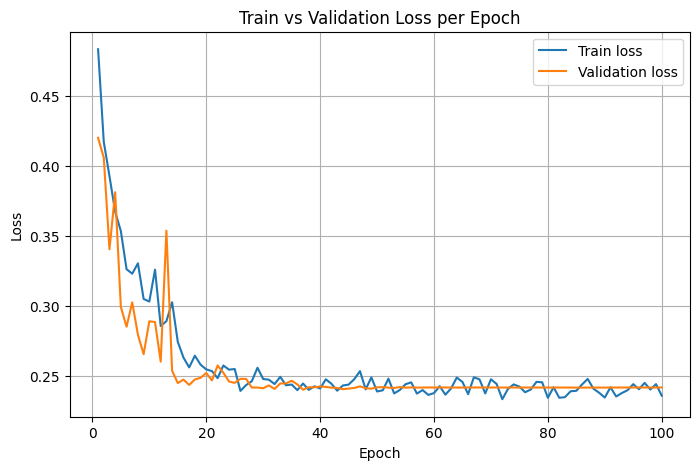

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(range(1, EPOCHS + 1), history["train_loss"], label="Train loss")
plt.plot(range(1, EPOCHS + 1), history["val_loss"], label="Validation loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Train vs Validation Loss per Epoch")
plt.legend()
plt.grid(True)
plt.show()


## Testing

In [ ]:
from sklearn.metrics import precision_recall_curve
model.load_state_dict(best_state)
print(f"Best epoch {best_epoch}, val AUPRC {best_auprc:.4f}")

prec, rec, thr = precision_recall_curve(y_val.numpy(), best_val_probs)
f1 = 2 * prec * rec / (prec + rec + 1e-8)
threshold = thr[f1[:-1].argmax()]
print("Threshold chosen on val:", threshold)

model.eval()

test_probs = []
with torch.inference_mode():
    for x, y in tqdm(test_dataloader):
        x = x.to(device)
        logits = model(x).squeeze(1)
        test_probs.append(torch.sigmoid(logits).cpu().numpy())

y_prob = np.concatenate(test_probs) # (N,)
y_hat  = (y_prob >= threshold).astype(int)
y_true = y_test.numpy().astype(int)

print("Predicted 'Bad':", y_hat.sum())
print("Real 'Bad':", y_true.sum())
print("Shape:", y_true.shape, y_hat.shape)

print("AUPRC: ", average_precision_score(y_true, y_prob))
baseline = y_true.mean()
print(f"Random Baseline ('Bad' %): {baseline:.4f}")
print("Accuracy:", accuracy_score(y_true, y_hat))
print(confusion_matrix(y_true, y_hat))
print(classification_report(y_true, y_hat, target_names=["good", "bad"]))

Best epoch 42, val AUPRC 0.9354
Threshold chosen on val: 0.3692631


  0%|          | 0/13 [00:00<?, ?it/s]

Predicted 'Bad': 63
Real 'Bad': 71
Shape: (197,) (197,)
AUPRC:  0.8941518261968037
Random Baseline ('Bad' %): 0.3604
Accuracy: 0.8984771573604061
[[120   6]
 [ 14  57]]
              precision    recall  f1-score   support

        good       0.90      0.95      0.92       126
         bad       0.90      0.80      0.85        71

    accuracy                           0.90       197
   macro avg       0.90      0.88      0.89       197
weighted avg       0.90      0.90      0.90       197



### Bootstrap resampling on the test set
95% confidence interval for the test AUPRC. Predictions are saved so models can be compared in `Compare_Models.ipynb`.

In [ ]:
from bootstrap import bootstrap_auprc

patient_ids = test_df["patient_id"].values.astype(str) # same order as y_true / y_prob
os.makedirs("results", exist_ok=True) # exist_ok = True so it doesn't flag an error when folder already exists
np.savez("results/baseline.npz", y_true=y_true, y_prob=y_prob, patient_ids=patient_ids)

lo, hi, std = bootstrap_auprc(y_true, y_prob, patient_ids)
print(f"Test AUPRC: {average_precision_score(y_true, y_prob):.4f} ± {std:.4f}  95% CI [{lo:.4f} - {hi:.4f}]")


What does the result say us?

Say for example the result is: Test AUPRC: 0.894  95% CI [0.846 - 0.935]
Then we know that the testset achieves 0,894 on our testset. But if you had another testset with the same size (with some other patients out of the population) it's AUPRC would lay somewhere between 0.846 and 0.935